<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/notebooks/notebooks/06_feature_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Loading in CLean data
!pip install -q imbalanced-learn

from google.colab import drive
drive.mount('/content/drive')
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import f1_score, recall_score, classification_report

import time
import pandas as pd
import numpy as np

path = '/content/drive/MyDrive/Datasets/'
train = pd.read_csv(path + 'train_clean.csv')
test  = pd.read_csv(path + 'test_clean.csv')
print(train.shape, test.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(107740, 43) (82332, 43)


In [ ]:
#Skill ut X som er features og Y somer fasit

X_train = train.drop(columns=['label', 'attack_cat'])
y_train = train['attack_cat']
X_test  = test.drop(columns=['label', 'attack_cat'])
y_test  = test['attack_cat']

In [ ]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
print(y_tr.value_counts())

attack_cat
Normal            41512
Exploits          15875
Fuzzers           12920
Reconnaissance     6018
Generic            3345
DoS                3045
Analysis           1275
Backdoor           1228
Shellcode           873
Worms               101
Name: count, dtype: int64


In [ ]:
#Del kolonnene i grupper

cat_cols = ['proto', 'service', 'state']
num_cols = X_tr.columns.drop(cat_cols).tolist()

skew = X_tr[num_cols].skew()
skew_cols  = skew[skew.abs() > 1].index.tolist()
other_cols = [c for c in num_cols if c not in skew_cols]

print(len(cat_cols), len(skew_cols), len(other_cols))

3 32 6


In [ ]:
# Bygg preprossesering

preprocess = ColumnTransformer([
    ('cat',  OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('skew', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                       ('scale', StandardScaler())]), skew_cols),
    ('num',  StandardScaler(), other_cols),
])

In [ ]:
resultater = []
sma_klasser = ['Worms', 'Shellcode', 'Backdoor', 'Analysis', 'DoS']

def kjor_eksperiment(navn, pipeline, features=None):
    if features is None:                                   # NY
        features = X_tr.columns.tolist()                   # NY
    start = time.time()
    pipeline.fit(X_tr[features], y_tr)                     # NY: bare valgte kolonner
    tid = time.time() - start

    y_pred = pipeline.predict(X_val[features])             # NY
    rad = {'Eksperiment': navn,
           'Antall features': len(features),               # NY
           'Macro-F1': f1_score(y_val, y_pred, average='macro'),
           'Treningstid (s)': round(tid, 1)}
    for k, r in zip(sma_klasser, recall_score(y_val, y_pred, labels=sma_klasser, average=None)):
        rad[f'Recall {k}'] = r
    resultater.append(rad)

    print(classification_report(y_val, y_pred, digits=3, zero_division=0))
    return pipeline

def ny_rf(**kw):
    return RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, **kw)

smote = SMOTE(sampling_strategy={'Worms': 3000, 'Shellcode': 3000, 'Backdoor': 3000,
                                 'Analysis': 3000, 'DoS': 5000},
              random_state=42)

In [ ]:
#Korrelasjon

corr = X_tr[num_cols].corr().abs()

# Behold bare øvre trekant av matrisen
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

par = upper.stack()
par = par[par > 0.95].sort_values(ascending=False)
print(par)

sbytes  sloss     0.996854
dbytes  dloss     0.996545
swin    dwin      0.987361
dpkts   dloss     0.976586
spkts   sloss     0.975057
dpkts   dbytes    0.970384
spkts   sbytes    0.967971
dtype: float64


Hvis A ≈ B og A ≈ C, er alle tre nesten like, så det holder å beholde én per gruppe. Det betyr at 5 features kan fjernes (41 → 36).

Hvilken beholdes? Velg den i hver gruppe som er mest informativ om attack_cat. Det finner du med neste metode.

In [ ]:
from sklearn.feature_selection import mutual_info_classif

# MI krever tall, så de kategoriske kolonnene gjøres om til heltallskoder
X_mi = X_tr.copy()
for c in cat_cols:
    X_mi[c] = X_mi[c].astype('category').cat.codes

diskret = [c in cat_cols for c in X_mi.columns]

start = time.time()
mi = mutual_info_classif(X_mi, y_tr, discrete_features=diskret, random_state=42)
print(f'Tid: {time.time() - start:.0f} s')

mi = pd.Series(mi, index=X_mi.columns).sort_values(ascending=False)
print(mi.round(3))

korr_fjern = ['spkts', 'sloss', 'dpkts', 'dloss', 'dwin']

Tid: 41 s
sbytes               0.872
dbytes               0.668
smean                0.615
dmean                0.541
sttl                 0.521
sload                0.481
dttl                 0.462
ct_state_ttl         0.460
dpkts                0.424
dload                0.424
rate                 0.416
dinpkt               0.416
dur                  0.383
synack               0.378
tcprtt               0.373
ackdat               0.359
sinpkt               0.319
dloss                0.315
djit                 0.295
sjit                 0.294
spkts                0.293
ct_srv_dst           0.278
sloss                0.255
service              0.248
ct_srv_src           0.237
ct_dst_src_ltm       0.213
ct_dst_ltm           0.197
state                0.183
proto                0.164
ct_src_ltm           0.153
ct_dst_sport_ltm     0.141
ct_src_dport_ltm     0.125
response_body_len    0.108
stcpb                0.079
swin                 0.077
dwin                 0.076
dtcpb             

Valget mellom swin og dwin er i praksis vilkårlig, siden MI-verdiene er nesten like.


In [ ]:
p_imp = ImbPipeline([('prep', preprocess), ('smote', smote), ('clf', ny_rf())])
p_imp.fit(X_tr, y_tr)

navn = p_imp.named_steps['prep'].get_feature_names_out()
imp  = p_imp.named_steps['clf'].feature_importances_

def original(n):
    n = n.split('__', 1)[1]              # 'cat__proto_tcp' -> 'proto_tcp'
    for c in cat_cols:
        if n.startswith(c + '_'):        # 'proto_tcp' -> 'proto'
            return c
    return n                             # numeriske er allerede riktige

rf_imp = (pd.Series(imp, index=[original(n) for n in navn])
            .groupby(level=0).sum()
            .sort_values(ascending=False))
print(rf_imp.round(3))

sttl                 0.065
sbytes               0.063
ct_state_ttl         0.059
smean                0.055
service              0.043
ct_srv_dst           0.041
dload                0.041
sload                0.040
dbytes               0.039
ct_dst_src_ltm       0.038
dmean                0.036
ct_srv_src           0.034
rate                 0.030
dur                  0.029
synack               0.029
sinpkt               0.028
tcprtt               0.028
ackdat               0.028
dttl                 0.028
sjit                 0.021
ct_src_ltm           0.020
proto                0.019
dpkts                0.019
djit                 0.018
dinpkt               0.018
dloss                0.014
stcpb                0.013
ct_dst_ltm           0.013
dtcpb                0.013
state                0.012
sloss                0.012
spkts                0.011
ct_dst_sport_ltm     0.011
ct_src_dport_ltm     0.010
response_body_len    0.007
ct_flw_http_mthd     0.005
trans_depth          0.005
s

Det viktigste funnet: RF har sttl på 1. plass og ct_state_ttl på 3. plass. Modellen lener seg altså tyngst på TTL-informasjon. Det gjør del C (med og uten TTL) til en av de viktigste testene i hele prosjektet.

Begrensning å nevne i rapporten: RF-importance (impurity-basert) favoriserer kontinuerlige features med mange unike verdier, og den måles på treningsdata. Permutation importance på valideringssettet er et mer robust alternativ, men tregere.

In [ ]:
# Felles Rangering
rang = pd.DataFrame({'MI': mi.rank(ascending=False),
                     'RF': rf_imp.rank(ascending=False)})
rang['Snitt'] = rang.mean(axis=1)
rang = rang.sort_values('Snitt')

print(rang)
print('Spearman-korrelasjon MI vs RF:', round(rang['MI'].corr(rang['RF'], method='spearman'), 3))

rangering = [f for f in rang.index if f not in korr_fjern]
print(len(rangering), 'features i rangeringen')

                     MI    RF  Snitt
sbytes              1.0   2.0    1.5
sttl                5.0   1.0    3.0
smean               3.0   4.0    3.5
ct_state_ttl        8.0   3.0    5.5
dbytes              2.0   9.0    5.5
sload               6.0   8.0    7.0
dmean               4.0  11.0    7.5
dload              10.0   7.0    8.5
rate               11.0  13.0   12.0
dttl                7.0  19.0   13.0
dur                13.0  14.0   13.5
ct_srv_dst         22.0   6.0   14.0
service            24.0   5.0   14.5
synack             14.0  15.0   14.5
tcprtt             15.0  17.0   16.0
dpkts               9.0  23.0   16.0
sinpkt             17.0  16.0   16.5
ackdat             16.0  18.0   17.0
ct_dst_src_ltm     26.0  10.0   18.0
dinpkt             12.0  25.0   18.5
ct_srv_src         25.0  12.0   18.5
sjit               20.0  20.0   20.0
djit               19.0  24.0   21.5
dloss              18.0  26.0   22.0
proto              29.0  22.0   25.5
ct_src_ltm         30.0  21.0   25.5
s

In [ ]:
#Preprocess som tilpasser feature listen

def lag_preprocess(features):
    cat   = [c for c in cat_cols   if c in features]
    skew  = [c for c in skew_cols  if c in features]
    other = [c for c in other_cols if c in features]
    return ColumnTransformer([
        ('cat',  OneHotEncoder(handle_unknown='ignore'), cat),
        ('skew', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                           ('scale', StandardScaler())]), skew),
        ('num',  StandardScaler(), other),
    ])

In [ ]:
#Kjør topp k

for k in [5, 10, 15, 20, 30, 36]:
    features = rangering[:k]
    p = ImbPipeline([('prep',  lag_preprocess(features)),
                     ('smote', smote),
                     ('clf',   ny_rf())])
    kjor_eksperiment(f'Topp {k}', p, features)

# Referanse: alle 41 features, uten korrelasjonsfjerning
alle = X_tr.columns.tolist()
p = ImbPipeline([('prep', lag_preprocess(alle)), ('smote', smote), ('clf', ny_rf())])
kjor_eksperiment('Alle 41', p, alle)

                precision    recall  f1-score   support

      Analysis      0.162     0.696     0.263       319
      Backdoor      0.356     0.218     0.271       307
           DoS      0.491     0.331     0.396       761
      Exploits      0.830     0.798     0.814      3969
       Fuzzers      0.701     0.666     0.683      3230
       Generic      0.946     0.843     0.892       836
        Normal      0.922     0.902     0.912     10378
Reconnaissance      0.853     0.713     0.777      1504
     Shellcode      0.419     0.697     0.523       218
         Worms      0.338     0.962     0.500        26

      accuracy                          0.797     21548
     macro avg      0.602     0.683     0.603     21548
  weighted avg      0.828     0.797     0.808     21548

                precision    recall  f1-score   support

      Analysis      0.163     0.599     0.256       319
      Backdoor      0.241     0.228     0.234       307
           DoS      0.485     0.285     0.35

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['proto', 'service',
                                                   'state']),
                                                 ('skew',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sload', 'dload', 'sloss',
                                                   'dloss', 'sinpk...
                                                   'ct_src_dport_ltm',
                                                   'ct_dst_sport_ltm',
                                                   'ct_dst_src_ltm',
                                                   'ct_ftp_cmd',
                                                   'ct_flw_http_mthd',
                                                   'ct_src_ltm', ...]),
                                                 ('num', StandardScaler(),
                                                  ['sttl', 'dttl', 'swin',
                                                   'stcpb', 'dtcpb',
                                                   'dwin'])])),
                ('smote',
                 SMOTE(random_state=42,
                       sampling_strategy={'Analysis': 3000, 'Backdoor': 3000,
                                          'DoS': 5000, 'Shellcode': 3000,
                                          'Worms': 3000})),
                ('clf', RandomForestClassifier(n_jobs=-1, random_state=42))])

             Antall features  Macro-F1  Treningstid (s)  Recall Worms  \
Eksperiment                                                             
Topp 5                     5     0.603              9.8         0.962   
Topp 10                   10     0.576             18.5         0.692   
Topp 15                   15     0.593             23.4         0.692   
Topp 20                   20     0.602             29.7         0.692   
Topp 30                   30     0.576             30.3         0.615   
Topp 36                   36     0.573             30.9         0.654   
Alle 41                   41     0.572             30.3         0.538   

             Recall Shellcode  Recall Backdoor  Recall Analysis  Recall DoS  
Eksperiment                                                                  
Topp 5                  0.697            0.218            0.696       0.331  
Topp 10                 0.463            0.228            0.599       0.285  
Topp 15                 0.642 

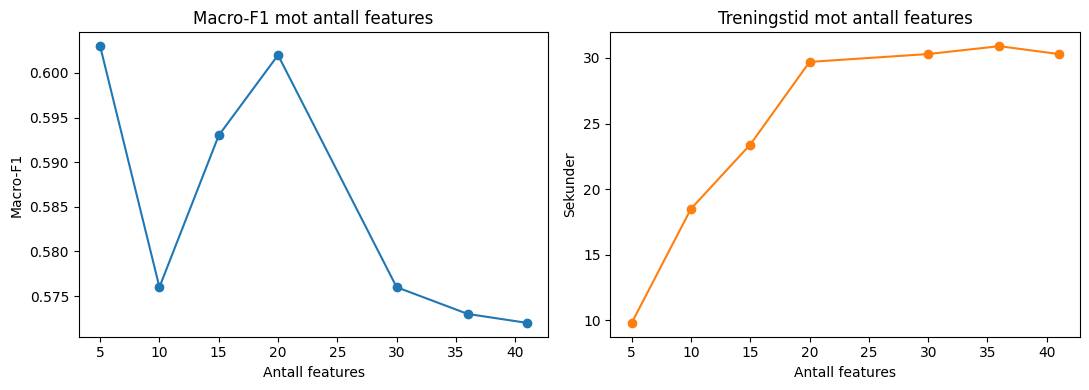

In [ ]:
#Tabell og plott

import matplotlib.pyplot as plt

tabell_k = pd.DataFrame(resultater).set_index('Eksperiment').round(3)
print(tabell_k)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(tabell_k['Antall features'], tabell_k['Macro-F1'], marker='o')
ax1.set_xlabel('Antall features'); ax1.set_ylabel('Macro-F1'); ax1.set_title('Macro-F1 mot antall features')
ax2.plot(tabell_k['Antall features'], tabell_k['Treningstid (s)'], marker='o', color='tab:orange')
ax2.set_xlabel('Antall features'); ax2.set_ylabel('Sekunder'); ax2.set_title('Treningstid mot antall features')
plt.tight_layout(); plt.show()